<a href="https://colab.research.google.com/github/LetheeshBalaji/DEEP-LEARNING/blob/main/24BAD063_Exp_5_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#24BAD063
#Letheesh Balaji


In [1]:
!pip uninstall -y datasets
!pip install datasets==3.6.0

Found existing installation: datasets 4.8.5
Uninstalling datasets-4.8.5:
  Successfully uninstalled datasets-4.8.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 18.0 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
ERROR: pip's dependency resolver does not currently take into account a

In [2]:
# ============================================
# TASK A: DATASET PREPARATION
# ============================================

# Install required libraries

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Student Roll Number
ROLL_NO = "24BAD063"

print("Roll Number:", ROLL_NO)

# --------------------------------------------
# 1. Load Tiny Shakespeare Dataset
# --------------------------------------------

dataset = load_dataset("karpathy/tiny_shakespeare")

print(dataset)

# Extract training text
text = dataset["train"][0]["text"]

print("\nFirst 1000 characters:\n")
print(text[:1000])

print("\nTotal characters:", len(text))

Roll Number: 24BAD063


README.md:   0%|          | 0.00/6.10k [00:00<?, ?B/s]

tiny_shakespeare.py:   0%|          | 0.00/3.73k [00:00<?, ?B/s]

The repository for karpathy/tiny_shakespeare contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/karpathy/tiny_shakespeare.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


Generating train split:   0%|          | 0/1 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 1
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 1
    })
    test: Dataset({
        features: ['text'],
        num_rows: 1
    })
})

First 1000 characters:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the le

In [3]:
# --------------------------------------------
# 2. Convert text to lowercase
# --------------------------------------------

text = text.lower()

print("First 500 characters after lowercase:\n")
print(text[:500])


# --------------------------------------------
# 3. Tokenization
# --------------------------------------------

tokenizer = Tokenizer(
    oov_token="<OOV>",
    filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n'
)

tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("\nVocabulary Size:", total_words)

print("\nFirst 20 words in vocabulary:")
print(list(tokenizer.word_index.items())[:20])

First 500 characters after lowercase:

first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us kill him, and we'll have corn at our own price.
is't a verdict?

all:
no more talking on't; let it be done: away, away!

second citizen:
one word, good citizens.

first citizen:
we are accounted poor

Vocabulary Size: 11915

First 20 words in vocabulary:
[('<OOV>', 1), ('the', 2), ('and', 3), ('to', 4), ('i', 5), ('of', 6), ('my', 7), ('you', 8), ('a', 9), ('that', 10), ('in', 11), ('is', 12), ('not', 13), ('for', 14), ('with', 15), ('it', 16), ('me', 17), ('your', 18), ('be', 19), ('his', 20)]


In [4]:
# --------------------------------------------
# 4. Convert text into integer sequences
# --------------------------------------------

input_sequences = []

# Split text into sentences
sentences = text.split("\n")

for sentence in sentences:

    # Convert words to integers
    token_list = tokenizer.texts_to_sequences([sentence])[0]

    # Generate n-gram sequences
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i + 1]
        input_sequences.append(n_gram_sequence)

print("Total input sequences:", len(input_sequences))

print("\nExample sequences:")
for seq in input_sequences[:5]:
    print(seq)

Total input sequences: 154531

Example sequences:
[88, 249]
[144, 35]
[144, 35, 963]
[144, 35, 963, 146]
[144, 35, 963, 146, 610]


In [5]:
# --------------------------------------------
# 5. Apply Padding
# --------------------------------------------

max_sequence_len = max(len(seq) for seq in input_sequences)

print("Maximum sequence length:", max_sequence_len)

input_sequences = np.array(
    pad_sequences(
        input_sequences,
        maxlen=max_sequence_len,
        padding="pre"
    )
)

print("Shape after padding:", input_sequences.shape)

Maximum sequence length: 16
Shape after padding: (154531, 16)


In [6]:
# --------------------------------------------
# 6. Separate input and output
# --------------------------------------------

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nExample:")
print("Input:", X[0])
print("Target:", y[0])

X shape: (154531, 15)
y shape: (154531,)

Example:
Input: [ 0  0  0  0  0  0  0  0  0  0  0  0  0  0 88]
Target: 249


In [7]:
# --------------------------------------------
# 7. Train-validation split
# --------------------------------------------

split = int(0.9 * len(X))

X_train = X[:split]
y_train = y[:split]

X_val = X[split:]
y_val = y[split:]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 139077
Validation samples: 15454


In [8]:
# ============================================
# TASK B: RNN MODEL
# ============================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# --------------------------------------------
# 1. Create RNN model
# --------------------------------------------

model = Sequential([

    # Convert words into dense vectors
    Embedding(
        input_dim=total_words,
        output_dim=128,
        input_length=max_sequence_len - 1
    ),

    # Learn sequential dependencies
    SimpleRNN(128),

    # Predict next word
    Dense(total_words, activation="softmax")
])

# --------------------------------------------
# 2. Compile model
# --------------------------------------------

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# --------------------------------------------
# 3. Display model summary
# --------------------------------------------

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [9]:
# ============================================
# TASK C: TRAINING
# ============================================

EPOCHS = 20
BATCH_SIZE = 128

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

Epoch 1/20
1087/1087 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - accuracy: 0.0496 - loss: 6.7730 - val_accuracy: 0.0676 - val_loss: 6.4534
Epoch 2/20
1087/1087 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.0878 - loss: 6.0592 - val_accuracy: 0.0844 - val_loss: 6.3292
Epoch 3/20
1087/1087 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.1022 - loss: 5.7058 - val_accuracy: 0.0897 - val_loss: 6.3504
Epoch 4/20
1087/1087 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.1140 - loss: 5.4207 - val_accuracy: 0.0902 - val_loss: 6.4063
Epoch 5/20
1087/1087 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1252 - loss: 5.1728 - val_accuracy: 0.0890 - val_loss: 6.4867
Epoch 6/20
1087/1087 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.1385 - loss: 4.9508 - val_accuracy: 0.0873 - val_loss: 6.5657
Epoch 7/20
1087/1087 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.1552 - loss: 4.7472 - val_accuracy: 0.0869 - val_loss: 6.6515
Epoch 8/20
1087/1087 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1747 - loss: 4.5553 -

In [10]:
# --------------------------------------------
# Final Training and Validation Metrics
# --------------------------------------------

train_loss, train_accuracy = model.evaluate(
    X_train,
    y_train,
    verbose=0
)

val_loss, val_accuracy = model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print("================================")
print("FINAL MODEL PERFORMANCE")
print("================================")

print(f"Training Loss      : {train_loss:.4f}")
print(f"Training Accuracy  : {train_accuracy:.4f}")

print(f"Validation Loss    : {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")

FINAL MODEL PERFORMANCE
Training Loss      : 3.8650
Training Accuracy  : 0.2609
Validation Loss    : 7.6776
Validation Accuracy: 0.0674


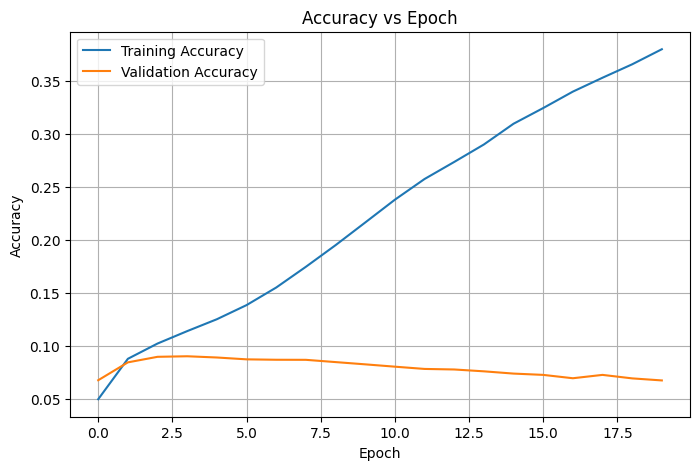

In [11]:
# ============================================
# ACCURACY VS EPOCH
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

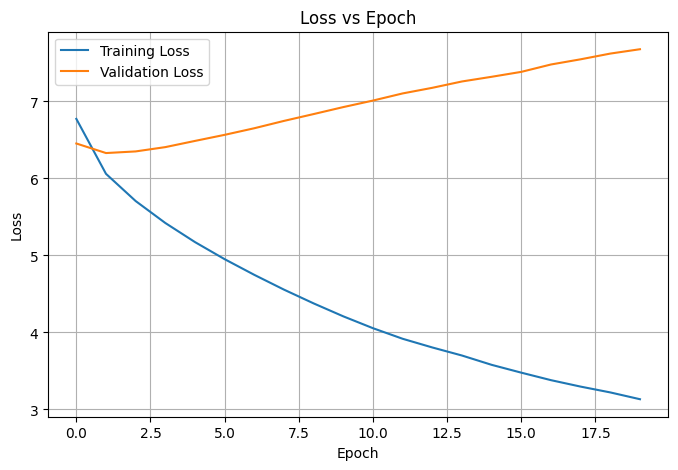

In [12]:
# ============================================
# LOSS VS EPOCH
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

In [13]:
# ============================================
# TASK D: TEXT GENERATION
# ============================================

def generate_text(seed_text, next_words, model, tokenizer, max_sequence_len):

    generated_text = seed_text

    for _ in range(next_words):

        # Convert seed text into integers
        token_list = tokenizer.texts_to_sequences(
            [generated_text]
        )[0]

        # Pad sequence
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding="pre"
        )

        # Predict probability of next word
        predicted_probs = model.predict(
            token_list,
            verbose=0
        )[0]

        # Get word with highest probability
        predicted_word_index = np.argmax(predicted_probs)

        # Convert index back to word
        output_word = ""

        for word, index in tokenizer.word_index.items():

            if index == predicted_word_index:
                output_word = word
                break

        # Add predicted word
        generated_text += " " + output_word

    return generated_text

In [14]:
# --------------------------------------------
# Sample 1
# --------------------------------------------

seed_text = "to be or not"

generated = generate_text(
    seed_text,
    30,
    model,
    tokenizer,
    max_sequence_len
)

print("Generated Text 1:")
print(generated)

Generated Text 1:
to be or not a scourge to telling thee more than i have heard the prince of lancaster afford false report of my son and i have heard the duke of norfolk sprightfully and


In [15]:
# --------------------------------------------
# Sample 2
# --------------------------------------------

seed_text = "the king"

generated = generate_text(
    seed_text,
    30,
    model,
    tokenizer,
    max_sequence_len
)

print("Generated Text 2:")
print(generated)

Generated Text 2:
the king enacts more than the basilisk of our own good lord of calais to be back'd with you and by thee by my distress was done to be thus still with


In [16]:
# --------------------------------------------
# Sample 3
# --------------------------------------------

seed_text = "my lord"

generated = generate_text(
    seed_text,
    30,
    model,
    tokenizer,
    max_sequence_len
)

print("Generated Text 3:")
print(generated)

Generated Text 3:
my lord he was a subject kill'd him autolycus who doth not give me leave awhile and to fight and take away to aught but more than i will fight with me


In [17]:
def generate_text_temperature(
    seed_text,
    next_words,
    model,
    tokenizer,
    max_sequence_len,
    temperature=0.7
):

    generated_text = seed_text

    # Reverse vocabulary for faster lookup
    index_word = {
        index: word
        for word, index in tokenizer.word_index.items()
    }

    for _ in range(next_words):

        token_list = tokenizer.texts_to_sequences(
            [generated_text]
        )[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding="pre"
        )

        predictions = model.predict(
            token_list,
            verbose=0
        )[0]

        # Apply temperature
        predictions = np.asarray(predictions).astype("float64")

        predictions = np.log(
            predictions + 1e-8
        ) / temperature

        exp_predictions = np.exp(
            predictions - np.max(predictions)
        )

        predictions = exp_predictions / np.sum(
            exp_predictions
        )

        # Sample next word
        predicted_index = np.random.choice(
            len(predictions),
            p=predictions
        )

        output_word = index_word.get(
            predicted_index,
            ""
        )

        generated_text += " " + output_word

    return generated_text

In [18]:
seeds = [
    "to be or not",
    "the king",
    "my lord"
]

for seed in seeds:

    print("\n" + "=" * 60)
    print("SEED:", seed)
    print("=" * 60)

    generated = generate_text_temperature(
        seed,
        30,
        model,
        tokenizer,
        max_sequence_len,
        temperature=0.7
    )

    print(generated)


SEED: to be or not
to be or not a visor for me i do this deed would die to fly like a villain love a thousand words have been deserved at him that are all mine honour and

SEED: the king
the king enacts more of her extremity was the king was it that i have taught me from the deep heart of parents you'ld mistrust me sir from me and the true

SEED: my lord
my lord a very caitiff married of it now kill'd the devil's crest up the world's competency hurl'd heated request surmise obstacles upon dates and bottom beats to his majesty obedient if
